# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MEDOXIII/FlyRank-Internship-ML/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## Abstract

Which pages of one client site should a reviewer open first? This study uses an anonymized slice of 30,000 pages from 32 clients (26,612 in scope), with a same-window decline proxy as the label. A logistic regression, scored out-of-fold under client-grouped validation, is compared with a transparent rule, random order and a one-signal ordering (lowest CTR within the position band) inside each client's own queue. Across 16 validated clients the model's median Precision@20 is 0.800 against 0.475 for the rule and 0.587 for random order, but the one-signal ordering scores as well (0.825), so the model is not shown to add value over it. The result is a human-review playbook that starts from the transparent ordering; it is a same-window ranking, not a future forecast or causal evidence.

**Extended abstract.**

**Problem.** A content team cannot review every page. The decision supported here is the order in which one client's pages are reviewed, so the metric is Precision@20 inside that client's queue.

**Setting.** An anonymized slice of 30,000 pages from 32 pseudonymous clients (trailing-90-day aggregates, no calendar dates). 26,612 pages are in scope and 16,617 are ranked pages across 28 clients. The label is a same-window *decline proxy*: impressions in the latest 30 days fell by more than 20% against the previous 30. The model is trained and scored on in-scope pages only, and validation is grouped by client.

**Approach.** A logistic regression on 26 page-level features is scored out-of-fold under five client-grouped folds and compared, on identical pages, with a transparent rule (age at least 180 days and at least 500 impressions), with random order and, as a stress test, with a one-signal ordering (lowest CTR within the page's position band first).

**Evidence.** Across the 16 validated clients, median Precision@20 is 0.800 for the model, 0.475 for the rule and 0.587 for random order, with median AUC 0.640. At K = 20 the model exceeds random order in 15 of 16 validated clients and the Week-4 rule in 14 of 16, and its median Precision@K is above client prevalence at every tested depth (K = 10, 20, 30, 50 and 75), although the share of clients above prevalence varies by depth. The one-signal ordering scored as well (median 0.825) and the model was strictly higher than it in only 4 of 16 clients, so the model is not shown to add value over that transparent ordering on the queue's own pages. Across three reported logistic-regression evaluations with different split and preprocessing choices, pooled Precision@50 ranged from 0.46 to 0.80; these figures provide context, not an apples-to-apples comparison. A deliberately leaked field drives the score to 0.999, which shows the audit can see a leak; a random split scored above client-grouped splits on average (AUC 0.692 vs 0.641 ± 0.064 across ten seeds), by about one seed-to-seed spread. Among observable archetypes only low CTR for the page's position is consistently associated with the proxy; stale-but-visible pages declined less.

**Scope.** The label window overlaps the features' window, so results are within-window associations; no calendar dates exist for a time-forward test; no causal claim about a refresh or any edit is made; and the score has not been shown to add to reading the trend in analytics. The output is a human-review playbook, not an automated decision. Code, seeds, environment and a result-to-notebook map are in Section 7.

## Setup

*Repo root, imports, one load of the raw file. Nothing here is a result.*

In [1]:
import os, sys, subprocess, json, warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/MEDOXIII/FlyRank-Internship-ML"
REPO_DIR = "FlyRank-Internship-ML"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    # walk up to the repo root (the folder that contains data/raw)
    while not os.path.isdir("data/raw") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED, KS, AGE_T, IMP_T = 42, (20, 50, 100), 180, 500
RAW_PATH = Path("data/raw/content_refresh_anonymized.csv")
assert RAW_PATH.exists(), "starter CSV not found - run from the repo root"

df = pd.read_csv(RAW_PATH)
y = df["trend_direction"].eq("down").astype(int)          # current decline proxy
groups = df["client_id"].astype(str)
imp90 = pd.to_numeric(df["impressions_90d"], errors="coerce")
prev30 = pd.to_numeric(df["impressions_prev_30d"], errors="coerce")
in_scope = prev30.gt(0)          # scope rule only, never a feature
visible = imp90.ge(IMP_T)

print("Working dir:", os.getcwd())
print(f"loaded {len(df):,} rows x {df.shape[1]} cols")

Working dir: d:\Projects\FlyRank-Internship-ML\FlyRank-Internship-ML
loaded 30,000 rows x 44 cols


## 1. Question

*This section is the paper's Introduction.*

**Problem.** Content programs such as FlyRank's manage many client sites, and a reviewer can open only a limited number of pages per cycle. FlyRank's public data report advises reviewing aging pages before they decline. This study asks a narrower question that its own slice can test.

**A concrete case.** Picture a reviewer with one afternoon for a client whose site holds thousands of pages (the largest client in this slice has 7,008). She can open about 20. If she opens 20 at random, about 6 in 10 of them already carry the decline proxy in this slice (a median prevalence of 0.587), so the real question is how much a ranking adds over that. This scenario is illustrative.

**Research question.** Can observable page-level search and engagement signals help a content team prioritize which pages to review first on one client site?

**Decision supported.** Which pages a reviewer opens first in a review cycle.
**Who acts.** An SEO or content team working on one client at a time.
**Cost of a wrong call.** Review time spent on a page that needed nothing while a more useful page waits. Nothing is changed automatically, so the cost is attention, not a live edit.

**Claims.** Each claim carries its own boundary and points to the section that supports it.
- **C1 (Sections 3 and 4).** Inside a client's own queue, scored out-of-fold, the model's Precision@20 is, at K = 20, above random order in 15 of 16 validated clients (median 0.800 vs 0.587) and above the Week-4 rule in 14 of 16 (median 0.475), with median AUC 0.640. *Boundary:* ranked pages of 16 validated clients; a same-window decline proxy; the median model Precision@K is above client prevalence at every tested depth (K = 10, 20, 30, 50 and 75), although the share of clients above prevalence varies by depth (94% at K = 10 to 30, 100% at K = 50 and 75); deeper depths were not tested. This is not reliable superiority: across three reported logistic-regression evaluations with different split and preprocessing choices, pooled Precision@50 ranged from 0.46 to 0.80, which is context, not an apples-to-apples comparison.
- **C2 (Section 3).** The evaluation boundary matters, but less than a single split suggested: a deliberately leaked field drives the score to 0.999, so the audit can see a leak; a random split scored above client-grouped splits on average (AUC 0.692 vs 0.641 ± 0.064; Precision@50 0.90 vs 0.808 ± 0.068 across ten seeds), by about 0.8 and 1.4 seed-to-seed SDs, and the single grouped split (AUC 0.605, Precision@50 0.62) was a low draw. *Boundary:* the audit cannot remove the overlap between the feature window and the label window.
- **C3 (Sections 4 and 6).** Among observable archetypes only low CTR for the page's position is consistently associated with the proxy (+5.6 pp, higher in 12 of 16 eligible clients); stale-but-visible pages are associated with less decline (-11.8 pp, higher in 1 of 12). *Boundary:* a descriptive association inside this client mix, not a mechanism.
- **C4 (Section 4).** A transparent one-signal ordering (lowest CTR within the page's position band first) matched the model on the queue's own pages: median Precision@20 0.825 vs 0.800 on ranked pages (a gap of half of one pick), with the model strictly higher in 4 of 16 clients; on all in-scope pages the model was ahead, 0.850 vs 0.750 (strictly higher in 10 of 21). The model is therefore not shown to add value over this ordering where the queue is used. *Boundary:* the baseline was added after the verdict rule was fixed, so this is an exploratory stress test.

**Careful words.** Same-window ranking, not a future forecast or causal evidence. A predictive feature is not a search-ranking factor, and nothing here shows that fixing a page causes recovery. This is decision support.

In [2]:
pages_per_client = df.groupby("client_id").size()
print(f"pages: {len(df):,} | clients: {df['client_id'].nunique()} | "
      f"pages per client min/median/max: {pages_per_client.min()} / {pages_per_client.median():.0f} / {pages_per_client.max()}")
print("decision unit: one page inside ONE client's own queue (no cross-client ranking)")
print(f"current decline proxy (trend_direction == 'down'): base rate {y.mean():.3f} ({y.sum():,} of {len(y):,} pages)")
print("illustrative review capacity used below: 20 pages per client per cycle, 15 min per page (placeholders)")

pages: 30,000 | clients: 32 | pages per client min/median/max: 3 / 567 / 7008
decision unit: one page inside ONE client's own queue (no cross-client ranking)
current decline proxy (trend_direction == 'down'): base rate 0.542 (16,262 of 30,000 pages)
illustrative review capacity used below: 20 pages per client per cycle, 15 min per page (placeholders)


## 2. Data

**Release and tables.** One anonymized starter slice, `content_refresh_anonymized.csv`: one row per content page (`content_id`) for one of 32 pseudonymous clients (3 to 7,008 pages each). Every numeric column is a trailing-90-day aggregate ending at an undated export snapshot; the `_last_30d` / `_prev_30d` columns split the most recent 60 of those days. No page is younger than 90 days. The warehouse daily table was not used.

**Label.** `trend_direction == "down"`: impressions in the latest 30 days fell by more than 20% against the 30 days before (rebuilding the slice's own trend column from the two 30-day impression columns matches all 30,000 rows at a 20% threshold, checked below). It is a same-window proxy, not an observed future outcome.

**Time order.** Features and label come from the same snapshot: the 90-day features contain the latest 30 days that define the label. This is same-window decline-proxy scoring, so nothing here claims to predict a decline before it happens. A future claim needs earlier features and a later label, which this slice cannot supply because it has no calendar dates.

**Scope.** Pages with no impressions in the previous 30 days cannot be "down", so the proxy is undefined for them. They are out of scope (a scope rule, never a feature): 26,612 of 30,000 pages (88.7%) are in scope.

**Final model features (26), one list used everywhere.** The code cell below builds this list once and every later cell reuses it.
- Numeric (18): `search_volume`, `competition`, `cpc`, `word_count`, `char_count`, `log_impressions_90d`, `log_clicks_90d`, `log_sessions_90d`, `log_ai_sessions_90d`, `days_with_impressions`, `days_with_sessions`, `content_age_days`, `days_since_last_update`, `ctr`, `avg_position`, `engagement_rate`, `scroll_rate`, `ai_traffic_pct`.
- Categorical (8): `competition_level`, `content_type`, `main_intent`, `age_tier`, `freshness_tier`, `word_count_tier`, `impression_tier`, `position_tier`.

**Removed fields, and why.**
- `trend_direction`, `trend_pct`: the label's source.
- The six `_last_30d` / `_prev_30d` columns: they rebuild the label exactly.
- `provider_used`, `model_used`: content-generation metadata, not a page signal.
- `pageviews_90d`, `users_90d`, `engaged_sessions_90d`, `scroll_events_90d`: raw counts already summarized by kept rate features; keeping both double-counts the signal.
- `char_count_tier`, `age_tier_order`: duplicates of kept features.
- `content_id`, `client_id`: grouping and joining only.

**Gotchas handled.** Rate columns are percentages multiplied by 100. `avg_position == 0` means "no data", not rank zero (1,205 rows). Missingness is structural: `search_volume` is blank for every page of one content type and `word_count` is blank for 28.3% of another, so zero-filling would teach the model the content type. I use the raw values with median imputation and missingness indicators fitted inside each training fold.

**Public-safe.** IDs are pseudonymous and never printed. No row-level predictions are written to disk.

In [3]:
FEATURE_NUM_RAW = ["search_volume", "competition", "cpc", "word_count", "char_count",
                   "impressions_90d", "clicks_90d", "sessions_90d", "ai_sessions_90d",
                   "days_with_impressions", "days_with_sessions", "content_age_days",
                   "days_since_last_update", "ctr", "avg_position", "engagement_rate",
                   "scroll_rate", "ai_traffic_pct"]
FEATURE_CAT = ["competition_level", "content_type", "main_intent", "age_tier",
               "freshness_tier", "word_count_tier", "impression_tier", "position_tier"]
CONTEXT = ["content_id", "client_id"]
EXCLUDED_WHY = {
    "label source": ["trend_direction", "trend_pct"],
    "rebuilds the label (100% reconstruction)": ["impressions_last_30d", "clicks_last_30d", "sessions_last_30d",
                                                 "impressions_prev_30d", "clicks_prev_30d", "sessions_prev_30d"],
    "content-generation metadata, not a page signal": ["provider_used", "model_used"],
    "double-counts kept rate features": ["pageviews_90d", "users_90d", "engaged_sessions_90d", "scroll_events_90d"],
    "duplicate bucket of a kept feature": ["char_count_tier", "age_tier_order"]}
EXCLUDED = [c for cols in EXCLUDED_WHY.values() for c in cols]
LOG_COLS = ["impressions_90d", "clicks_90d", "sessions_90d", "ai_sessions_90d"]
MODEL_NUM = [("log_" + c) if c in LOG_COLS else c for c in FEATURE_NUM_RAW]
FINAL_FEATURES = MODEL_NUM + FEATURE_CAT

bucketed = FEATURE_NUM_RAW + FEATURE_CAT + CONTEXT + EXCLUDED
print(f"columns bucketed: {len(bucketed)} / raw columns: {df.shape[1]} | "
      f"not in any bucket: {sorted(set(df.columns) - set(bucketed)) or 'none'} | "
      f"double-bucketed: {len(bucketed) != len(set(bucketed))}")
print(f"\nFINAL MODEL FEATURES ({len(FINAL_FEATURES)}):")
print("  numeric (%d): %s" % (len(MODEL_NUM), ", ".join(MODEL_NUM)))
print("  categorical (%d): %s" % (len(FEATURE_CAT), ", ".join(FEATURE_CAT)))
print("REMOVED FIELDS:")
for why, cols in EXCLUDED_WHY.items():
    print(f"  {why}: {', '.join(cols)}")

print("\n-- grain and window --")
print("duplicate content_id rows:", int(df["content_id"].duplicated().sum()))
print("content_ids attached to >1 client:", int((df.groupby("content_id")["client_id"].nunique() > 1).sum()))
print("content_age_days min/max:", df["content_age_days"].min(), "/", df["content_age_days"].max())
fits = (df["impressions_last_30d"] + df["impressions_prev_30d"] <= df["impressions_90d"]).mean()
print(f"share of rows where last30d + prev30d <= 90d total: {fits:.4f}")
day_counts = {"days_since_last_update", "days_with_impressions", "days_with_sessions", "content_age_days"}
date_like = [c for c in df.columns if ("date" in c.lower() or "time" in c.lower()) and c not in day_counts]
print("columns naming an absolute date/timestamp:", date_like or "none")

print("\n-- why the six 30-day columns are excluded: they rebuild the label --")
last, prev = df["impressions_last_30d"], df["impressions_prev_30d"]
pct = (last - prev) / prev.where(prev.gt(0)) * 100
recon = np.select([prev.eq(0) & last.gt(0), prev.eq(0), pct.gt(20), pct.lt(-20)],
                  ["new", "flat", "up", "down"], default="stable")
print("reconstruction accuracy vs trend_direction:", round(float((recon == df["trend_direction"]).mean()), 4))

print("\n-- gotchas --")
print("avg_position == 0 (no data) rows:", int((df["avg_position"] == 0).sum()))
print("search_volume missing % by content_type:", df.groupby("content_type")["search_volume"].apply(lambda s: round(s.isna().mean() * 100, 1)).to_dict())
print("word_count missing % by content_type:", df.groupby("content_type")["word_count"].apply(lambda s: round(s.isna().mean() * 100, 1)).to_dict())
assert int(y[~in_scope].sum()) == 0, "a page with no previous-30-day impressions cannot be labelled down"
print(f"in scope (impressions in previous 30 days): {int(in_scope.sum()):,} of {len(df):,} ({in_scope.mean():.1%}); "
      f"proxy rate in scope {y[in_scope].mean():.3f}; 'down' pages out of scope: {int(y[~in_scope].sum())}")

columns bucketed: 44 / raw columns: 44 | not in any bucket: none | double-bucketed: False

FINAL MODEL FEATURES (26):
  numeric (18): search_volume, competition, cpc, word_count, char_count, log_impressions_90d, log_clicks_90d, log_sessions_90d, log_ai_sessions_90d, days_with_impressions, days_with_sessions, content_age_days, days_since_last_update, ctr, avg_position, engagement_rate, scroll_rate, ai_traffic_pct
  categorical (8): competition_level, content_type, main_intent, age_tier, freshness_tier, word_count_tier, impression_tier, position_tier
REMOVED FIELDS:
  label source: trend_direction, trend_pct
  rebuilds the label (100% reconstruction): impressions_last_30d, clicks_last_30d, sessions_last_30d, impressions_prev_30d, clicks_prev_30d, sessions_prev_30d
  content-generation metadata, not a page signal: provider_used, model_used
  double-counts kept rate features: pageviews_90d, users_90d, engaged_sessions_90d, scroll_events_90d
  duplicate bucket of a kept feature: char_count_

## 3. Methodology

**Assumptions.** A page's recent change in impressions is something a team can act on, and the 90-day features describe the page well enough to rank it. The features **overlap** the label window (the latest 30 days sit inside the 90), so every result is a within-window association.

**Features and model.** The 26 final features listed in Section 2 (one list, built once in code). Logistic regression with balanced class weights, chosen because it is readable and auditable. Its score ranks pages; it is not a calibrated probability.

**Validation.** Five-fold `GroupKFold` by client: no client is in train and test together, and every client is scored once by a model that never saw it (out-of-fold). Median imputation and missingness indicators are fitted inside each training fold. The queue is **per client**, so the main metrics are measured per client; whole-fold numbers pooled across clients are context only.

**Training scope.** The proxy is undefined for pages with no previous-30-day impressions, so the model is trained on in-scope pages only and only in-scope pages are evaluated; the 3,388 out-of-scope pages are never trained on or scored. Earlier notebooks (W03, W05, W06) trained on all pages, so their numbers are not directly comparable.

**Comparison contract.** The model and every baseline are scored on the same eligible pages, the same client folds, the same metric, the same review depth K and the same tie rule; the contract is printed next to the results in Section 4.

**Baselines.**
1. Random order, whose expected Precision@K is the prevalence.
2. The Week-4 rule: eligible if age is at least 180 days and impressions at least 500, ranked by impressions (ties: impressions, then older age, then `content_id`).
3. Added here as a stress test: lowest CTR within its position band first, using the CTR percentile inside each client (the LOW_CTR_FOR_POSITION archetype in Section 6 instead uses the lowest global quartile within the band among ranked pages, so the two are related but not identical). It uses no model, so it shows what a simple signal already gives. It was added after the verdict rule was fixed and after the Week-4 rule scored at or below random, so it is an exploratory comparison, not a pre-registered one.

**Metrics.** Precision@K against the prevalence, and ROC AUC. The verdict rule was fixed before looking at results: at least 8 validated clients, and AUC > 0.5 and Precision@20 above prevalence in at least 70% of them. A client is validated if it has at least 100 ranked pages and at least 20 of each class.

**Leakage as a method, not an apology.** (1) Add `trend_pct` back on purpose: the score must jump toward perfect, proving the audit can see a leak (this is a test fixture, never a final feature). (2) Split the clean features into 90-day-window features and static features to see how much the overlap contributes. (3) Compare a random split with a client-grouped split, and repeat the grouped split with ten seeds so one lucky draw does not carry the result. The forbidden columns are asserted absent from the feature list. These checks do not remove the window overlap.

In [4]:
NUM, CAT, FEATURES = list(MODEL_NUM), list(FEATURE_CAT), list(FINAL_FEATURES)      # one list, built in Section 2
assert FEATURES == NUM + CAT and len(FEATURES) == 26
FORBIDDEN = set(EXCLUDED) | {"content_id", "client_id", "is_declining_label", "measurable_opportunity"}
assert set(FEATURES).isdisjoint(FORBIDDEN), "forbidden column in the feature list"
assert not [c for c in FEATURES if "trend" in c or "30d" in c], "risky column name in the feature list"
print(f"feature list: {len(FEATURES)} ({len(NUM)} numeric + {len(CAT)} categorical); forbidden-column assertions passed")


def prep(frame):
    out = frame.copy()
    for c in LOG_COLS:
        out["log_" + c] = np.log1p(pd.to_numeric(out[c], errors="coerce").clip(lower=0))
    for c in NUM:
        out[c] = pd.to_numeric(out[c], errors="coerce").replace([np.inf, -np.inf], np.nan)
    out.loc[out["avg_position"].eq(0), "avg_position"] = np.nan      # 0 means "no data"
    for c in CAT:
        out[c] = out[c].fillna("unknown").astype(str).replace({"": "unknown", "nan": "unknown"})
    return out


def make_model(num, cat):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("pre", pre),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=5000, random_state=SEED))])


def p_at_k(yt, score, k):
    idx = np.argsort(-np.asarray(score), kind="mergesort")[:k]
    return float(np.asarray(yt)[idx].mean())


def rule_score(frame):
    imp = pd.to_numeric(frame["impressions_90d"], errors="coerce")
    return imp.where(frame["content_age_days"].ge(AGE_T) & imp.ge(IMP_T), 0.0).to_numpy()


def head_k(frame, score_col, k, tie_cols=(), tie_asc=()):
    keys = [score_col] + list(tie_cols) + ["content_id"]
    asc = [False] + list(tie_asc) + [True]
    return frame.sort_values(keys, ascending=asc, kind="mergesort").head(k)


def topk(frame, score_col, k, tie_cols=(), tie_asc=()):
    return float(head_k(frame, score_col, k, tie_cols, tie_asc)["y"].mean())


P = prep(df)

# ---- out-of-fold scores: every client is scored by a model that never saw it ----
# The proxy is undefined for pages with no previous-30-day impressions, so the model is TRAINED on in-scope pages only
# and only in-scope pages are ever evaluated. Folds are still cut by client on all pages.
IN = in_scope.to_numpy()
splits = list(GroupKFold(n_splits=5).split(P, y, groups=groups))
oof, fold_id = np.full(len(P), np.nan), np.zeros(len(P), dtype=int)
train_rows = []
for f, (tr, te) in enumerate(splits, start=1):
    assert set(groups.iloc[tr]).isdisjoint(set(groups.iloc[te])), "a client crossed train/test"
    tr_in = tr[IN[tr]]
    assert in_scope.iloc[tr_in].all(), "an out-of-scope page reached the training set"
    m = make_model(NUM, CAT).fit(P.iloc[tr_in][FEATURES], y.iloc[tr_in])
    oof[te] = m.predict_proba(P.iloc[te][FEATURES])[:, 1]
    fold_id[te] = f
    train_rows.append(int(len(tr_in)))
assert not np.isnan(oof).any()
oof = np.where(IN, oof, np.nan)          # out-of-scope pages are never evaluated
print("5 client-grouped folds fitted; test clients per fold:",
      [int(groups.iloc[te].nunique()) for _, te in splits], "| in-scope training rows per fold:", train_rows,
      "| out-of-fold scores kept in memory only")

# ---- one working frame (ids stay in memory, never printed) ----
Q = pd.DataFrame({
    "content_id": df["content_id"], "client_id": groups, "y": y, "oof": oof, "fold": fold_id,
    "rule": rule_score(df), "imp": imp90, "age": df["content_age_days"],
    "in_scope": in_scope, "visible": visible, "ranked": in_scope & visible,
    "ctr": pd.to_numeric(df["ctr"], errors="coerce"), "pos": P["avg_position"],
    "eng": pd.to_numeric(df["engagement_rate"], errors="coerce"),
    "dsu": pd.to_numeric(df["days_since_last_update"], errors="coerce")})
Q["band"] = pd.cut(Q["pos"], bins=[0, 3, 5, 10, 20, np.inf], labels=["(0,3]", "(3,5]", "(5,10]", "(10,20]", "(20,+)"])

# ---- leakage hunt (random vs grouped splits on the same features) ----
P["trend_pct"] = pd.to_numeric(df["trend_pct"], errors="coerce")      # deliberate leak, test fixture only
WINDOW_NUM = ["log_impressions_90d", "log_clicks_90d", "log_sessions_90d", "log_ai_sessions_90d",
              "days_with_impressions", "days_with_sessions", "ctr", "avg_position",
              "engagement_rate", "scroll_rate", "ai_traffic_pct"]
WINDOW_CAT = ["impression_tier", "position_tier"]
STATIC_NUM = [c for c in NUM if c not in WINDOW_NUM]
STATIC_CAT = [c for c in CAT if c not in WINDOW_CAT]
pos_in = np.flatnonzero(IN)                                   # leakage hunt also uses in-scope pages only
y_in, g_in = y.iloc[pos_in], groups.iloc[pos_in]
tr_r, te_r = train_test_split(pos_in, test_size=0.25, random_state=SEED, stratify=y_in)
_gtr, _gte = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(pos_in, y_in, groups=g_in))
tr_g, te_g = pos_in[_gtr], pos_in[_gte]


def score_split(num, cat, tr, te):
    m = make_model(num, cat).fit(P.iloc[tr][num + cat], y.iloc[tr])
    p = m.predict_proba(P.iloc[te][num + cat])[:, 1]
    yt = y.iloc[te].to_numpy()
    return roc_auc_score(yt, p), p_at_k(yt, p, 50)


W03 = {"clean, random split": (0.709, 0.86), "clean + trend_pct (deliberate leak), random split": (0.9996, 1.00),
       "90-day-window features only, random split": (0.667, 0.74), "static features only, random split": (0.634, 0.82),
       "clean, client-grouped split": (0.611, 0.74)}
runs = {"clean, random split": (NUM, CAT, tr_r, te_r),
        "clean + trend_pct (deliberate leak), random split": (NUM + ["trend_pct"], CAT, tr_r, te_r),
        "90-day-window features only, random split": (WINDOW_NUM, WINDOW_CAT, tr_r, te_r),
        "static features only, random split": (STATIC_NUM, STATIC_CAT, tr_r, te_r),
        "clean, client-grouped split": (NUM, CAT, tr_g, te_g)}
rows = []
for name, (num, cat, tr, te) in runs.items():
    auc, p50 = score_split(num, cat, tr, te)
    rows.append({"test": name, "AUC": auc, "P@50": p50, "W03_AUC": W03[name][0], "W03_P@50": W03[name][1]})
leak_table = pd.DataFrame(rows)
print(f"\nleakage hunt on in-scope pages (base rate {y[in_scope].mean():.3f}; W03 columns = earlier all-pages, zero-filled run, for reference only):")
print(leak_table.round(3).to_string(index=False))

# ---- grouped split repeated with ten seeds (one lucky draw must not carry the result) ----
seed_runs = []
for sd in range(10):
    _a, _b = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=sd).split(pos_in, y_in, groups=g_in))
    seed_runs.append(score_split(NUM, CAT, pos_in[_a], pos_in[_b]))
seed_auc, seed_p50 = np.array(seed_runs).T
print(f"clean, client-grouped 25% split, 10 seeds: AUC {seed_auc.mean():.3f} +/- {seed_auc.std(ddof=1):.3f} | "
      f"P@50 {seed_p50.mean():.3f} +/- {seed_p50.std(ddof=1):.3f} (SD across seeds; not a confidence interval)")

feature list: 26 (18 numeric + 8 categorical); forbidden-column assertions passed
5 client-grouped folds fitted; test clients per fold: [1, 7, 8, 8, 8] | in-scope training rows per fold: [19629, 21055, 22180, 21755, 21829] | out-of-fold scores kept in memory only

leakage hunt on in-scope pages (base rate 0.611; W03 columns = earlier all-pages, zero-filled run, for reference only):
                                             test   AUC  P@50  W03_AUC  W03_P@50
                              clean, random split 0.692  0.90    0.709      0.86
clean + trend_pct (deliberate leak), random split 0.999  1.00    1.000      1.00
        90-day-window features only, random split 0.634  0.82    0.667      0.74
               static features only, random split 0.632  0.86    0.634      0.82
                      clean, client-grouped split 0.605  0.62    0.611      0.74
clean, client-grouped 25% split, 10 seeds: AUC 0.641 +/- 0.064 | P@50 0.808 +/- 0.068 (SD across seeds; not a confidence interval

## 4. Results (vs baseline)

**Comparison contract (printed first in the cell below).** Eligible rows, feature window, label window, folds, metric, K and tie rule are the same for the model and every baseline; a baseline differs only in its score.

**Headline (supports C1): the queue unit, per client, out-of-fold, on ranked pages** (in scope and at least 500 impressions: 16,617 pages across 28 clients; 16 of them meet the validation size rule). The model's Precision@20 has a median of 0.800 against 0.475 for the Week-4 rule and 0.587 for the clients' own prevalence, which is 21.3 points above random order. It is above prevalence in 94% of the 16 clients and above the rule in 88%. Median AUC is 0.640 (IQR 0.607 to 0.649), above 0.5 in every validated client. Verdict under the pre-set rule: **SUPPORTED**. As a sensitivity run on all in-scope pages (21 validated clients), median AUC is 0.610 (above 0.5 in 90%) and Precision@20 is 0.850 versus 0.450 for the rule and 0.644 prevalence; the model is above prevalence in 90% of clients and above the rule in 86%.

**Where the advantage stops (boundary of C1).** The model's median Precision@K stays above prevalence at every depth tested: 0.800, 0.800, 0.800, 0.810 and 0.800 at K = 10, 20, 30, 50 and 75, against a prevalence of 0.587 (0.622 at K = 75, where 13 clients have at least 150 ranked pages). The share of clients above prevalence is 94% at K = 10 to 30 and 100% at K = 50 and 75. The rule sits between 0.400 and 0.507. Deeper depths were not tested.

**Stress test (supports C4).** On ranked pages the one-signal ordering (lowest CTR within the position band first) has a median Precision@20 of 0.825 against 0.800 for the model, a gap of 2.5 points, which is half of one pick at K = 20. It is above prevalence in 94% of clients, and the model is strictly higher in only 25% (4 of 16). On all in-scope pages the model leads, 0.850 against 0.750, and is strictly higher in 48% of 21 clients, with the one-signal ordering above prevalence in 76%. This baseline was added after the verdict rule was fixed, so it is an exploratory comparison.

**Leakage and split checks (supports C2).** On in-scope pages (base rate 0.611) the deliberate leak scores AUC 0.999 and Precision@50 1.00. A random split scores AUC 0.692 and Precision@50 0.90; window-only features 0.634 and 0.82; static-only features 0.632 and 0.86; a single client-grouped split 0.605 and 0.62. Repeating the grouped split with ten seeds gives AUC 0.641 ± 0.064 and Precision@50 0.808 ± 0.068 (SD across seeds), so the single grouped split was a low draw. The random-versus-grouped gaps are 0.05 in AUC (about 0.8 SD) and 0.09 in Precision@50 (about 1.4 SD).

**Context only: whole folds pooled across clients, in-scope pages.** Mean Precision@50 is 0.796 for the model versus 0.540 for the rule at a mean prevalence of 0.618; mean AUC is 0.595 (0.494 to 0.648 across folds). In fold 4 the pooled AUC is below chance (0.494) while Precision@50 (0.78) is above prevalence (0.737), so an advantage at the top of the list can coexist with no overall ranking skill. These pooled figures are inflated by client mix: the rule's top-50 queues came mostly from a single client, and the model's from a few. They should not be quoted as the queue's performance.

**Three reported evaluations.** Across three reported logistic-regression evaluations with different split and preprocessing choices (a 25% grouped split on all pages in W03, one six-client holdout on all pages in W05, and the five-fold mean here, trained and scored on in-scope pages only), pooled Precision@50 ranged from 0.46 to 0.80. These figures provide context, not an apples-to-apples comparison.

**Honest reading.** The model beats a weak baseline (the Week-4 rule is below random order on these pages) and beats random order, but on the queue's own pages it does not beat a one-signal ordering. The defensible reading is that the signal, low CTR for a page's position, carries most of the value, and the model adds little over it where the queue is used. Everything here is a within-window association with a proxy label.

In [5]:
# ---- comparison contract ----
contract = pd.DataFrame([
    ("eligible rows", "ranked pages: in scope (impressions in the previous 30 days) and >= 500 impressions in 90 days"),
    ("feature window", "trailing 90 days to the snapshot (contains the label window)"),
    ("label window", "latest 30 days vs previous 30 days, same snapshot (overlapping)"),
    ("folds", "GroupKFold(5) by client; metrics per validated client (>= 100 ranked pages and >= 20 of each class)"),
    ("metric and K", "Precision@20 (primary) and AUC; Precision@K for K = 10 to 75 in the curve"),
    ("tie rule", "model: score desc, then content_id asc | rule: score, impressions, older age, then content_id | CTR-in-band: score, then content_id"),
    ("baselines", "random order (= client prevalence); Week-4 rule (age >= 180 d and impressions >= 500, ranked by impressions)")],
    columns=["item", "same for model and baselines"])
print(contract.to_string(index=False))

# ---- whole-fold metrics (context) ----
rows = []
for f in range(1, 6):
    t = Q[Q["fold"].eq(f) & Q["in_scope"]]          # in-scope pages only: the proxy is undefined elsewhere
    row = {"fold": f, "clients": t["client_id"].nunique(), "pages": len(t), "prevalence": t["y"].mean(),
           "AUC": roc_auc_score(t["y"], t["oof"]), "AP": average_precision_score(t["y"], t["oof"])}
    for k in KS:
        row[f"model_P@{k}"] = topk(t, "oof", k)
        row[f"rule_P@{k}"] = topk(t, "rule", k, ("imp", "age"), (False, False))
    row["model_top50_share"] = head_k(t, "oof", 50)["client_id"].value_counts(normalize=True).iloc[0]
    row["rule_top50_share"] = head_k(t, "rule", 50, ("imp", "age"), (False, False))["client_id"].value_counts(normalize=True).iloc[0]
    rows.append(row)
folds = pd.DataFrame(rows)
print("\nwhole folds pooled across clients, in-scope pages only (CONTEXT ONLY; fold 1 is a single client):")
print(folds[["fold", "clients", "pages", "prevalence", "model_P@20", "model_P@50", "model_P@100",
             "rule_P@50", "AUC"]].round(3).to_string(index=False))
print("mean of folds:", folds[["prevalence", "model_P@20", "model_P@50", "model_P@100", "rule_P@20", "rule_P@50",
                               "rule_P@100", "AUC", "AP"]].mean().round(3).to_dict())
print(f"whole-fold AUC min/max: {folds['AUC'].min():.3f} / {folds['AUC'].max():.3f}")
print("top-50 queue, share of the largest client by fold: model", folds["model_top50_share"].round(2).tolist(),
      "| rule", folds["rule_top50_share"].round(2).tolist(), "(client mix inflates pooled precision)")
print("\nthree reported logistic-regression evaluations with different split and preprocessing choices (W03 and W05 quoted from the earlier all-pages notebooks; context, not an apples-to-apples comparison):")
print(pd.DataFrame({"evaluation": ["W03 grouped 25% split, all pages (quoted)", "W05 six-client holdout, all pages (quoted)", "capstone 5-fold mean (in-scope training and scoring)"],
                    "AUC": [0.611, 0.700, folds["AUC"].mean()],
                    "P@50": [0.74, 0.46, folds["model_P@50"].mean()]}).round(3).to_string(index=False))


# ---- per-client validation: the unit of the queue ----
def validated_ids(frame, min_pages=100, min_class=20):
    out = set()
    for cid, t in frame.groupby("client_id"):
        pos_n = int(t["y"].sum())
        if len(t) >= min_pages and pos_n >= min_class and len(t) - pos_n >= min_class:
            out.add(cid)
    return out


def per_client(frame, ks=(20, 50), min_pages=100, min_class=20):
    rows = []
    for _, t in frame.groupby("client_id"):
        pos_n = int(t["y"].sum())
        if len(t) < min_pages or pos_n < min_class or len(t) - pos_n < min_class:
            continue
        t = t.copy()      # one-signal ordering: lowest CTR percentile WITHIN THE CLIENT inside each position band first
        t["ctrband"] = (1 - t.groupby("band", observed=True)["ctr"].rank(pct=True)).fillna(-1)
        r = {"pages": len(t), "prevalence": t["y"].mean(), "AUC": roc_auc_score(t["y"], t["oof"])}
        for k in ks:
            r[f"model_P@{k}"] = topk(t, "oof", k)
            r[f"rule_P@{k}"] = topk(t, "rule", k, ("imp", "age"), (False, False))
            r[f"ctrband_P@{k}"] = topk(t, "ctrband", k)
        rows.append(r)
    return pd.DataFrame(rows)


def summarize(pc, label):
    s = {"scope": label, "clients": len(pc),
         "AUC_median": pc["AUC"].median(), "AUC_q1": pc["AUC"].quantile(0.25), "AUC_q3": pc["AUC"].quantile(0.75),
         "AUC>0.5": (pc["AUC"] > 0.5).mean(), "prevalence_median": pc["prevalence"].median(),
         "model_P@20": pc["model_P@20"].median(), "rule_P@20": pc["rule_P@20"].median(),
         "ctrband_P@20": pc["ctrband_P@20"].median(),
         "model>prevalence": (pc["model_P@20"] > pc["prevalence"]).mean(),
         "model>rule": (pc["model_P@20"] > pc["rule_P@20"]).mean(),
         "model>ctrband": (pc["model_P@20"] > pc["ctrband_P@20"]).mean(),
         "ctrband>prevalence": (pc["ctrband_P@20"] > pc["prevalence"]).mean()}
    s["verdict"] = "SUPPORTED" if (s["clients"] >= 8 and s["AUC>0.5"] >= 0.7 and s["model>prevalence"] >= 0.7) else "NOT SUPPORTED"
    return s


VALID_IDS = validated_ids(Q[Q["ranked"]])
pc_ranked = per_client(Q[Q["ranked"]])
pc_sens = per_client(Q[Q["in_scope"]])
assert len(VALID_IDS) == len(pc_ranked)
sum_ranked, sum_sens = summarize(pc_ranked, "ranked pages (the queue)"), summarize(pc_sens, "all in-scope pages (sensitivity)")
n_queued = Q.loc[Q["ranked"], "client_id"].nunique()
print(f"\nqueue population: {int(Q['ranked'].sum()):,} ranked pages across {n_queued} clients "
      f"({n_queued - len(VALID_IDS)} queued clients lack their own validation)")
print("per-client, out-of-fold (medians across validated clients; no client ids shown):")
print(pd.DataFrame([sum_ranked, sum_sens]).set_index("scope").T.to_string())
d = sum_ranked
verdict_line = ("the model beats the simple CTR-in-band baseline in most clients" if d["model>ctrband"] >= 0.7
                else "the model does NOT clearly beat the simple CTR-in-band baseline, so say only 'better than the rule and than random'")
print(f"\nstress test: median P@20 model {d['model_P@20']:.3f} vs lowest-CTR-in-band {d['ctrband_P@20']:.3f} "
      f"(model higher in {d['model>ctrband']:.0%} of clients; CTR-in-band above prevalence in {d['ctrband>prevalence']:.0%}) -> {verdict_line}.")

# ---- Precision@K curve: where the advantage is and where it stops (clients with >= 2K ranked pages) ----
CURVE_KS = (10, 20, 30, 50, 75)
Rk = Q[Q["ranked"] & Q["client_id"].isin(VALID_IDS)]
crow = []
for k in CURVE_KS:
    mv, rv, pv = [], [], []
    for _, t in Rk.groupby("client_id"):
        if len(t) < 2 * k:
            continue
        mv.append(topk(t, "oof", k))
        rv.append(topk(t, "rule", k, ("imp", "age"), (False, False)))
        pv.append(t["y"].mean())
    crow.append({"K": k, "clients": len(mv),
                 "model": float(np.median(mv)) if mv else np.nan, "rule": float(np.median(rv)) if rv else np.nan,
                 "prevalence": float(np.median(pv)) if pv else np.nan,
                 "model>prevalence": float(np.mean(np.array(mv) > np.array(pv))) if mv else np.nan})
curve_tbl = pd.DataFrame(crow)
print("\nPrecision@K, median across validated clients with >= 2K ranked pages:")
print(curve_tbl.round(3).to_string(index=False))
above = (curve_tbl["model"] > curve_tbl["prevalence"]).tolist()
if all(above):
    edge_msg = (f"the model's median Precision@K exceeds prevalence at every depth shown (K = {CURVE_KS[0]} to {CURVE_KS[-1]}); "
                "say that deeper depths were not tested")
else:
    first_bad = curve_tbl.loc[~curve_tbl["model"].gt(curve_tbl["prevalence"]), "K"].iloc[0]
    edge_msg = f"the model's median Precision@K stops exceeding prevalence at K = {int(first_bad)}"
print("C1 boundary sentence ->", edge_msg)

          item                                                                                                        same for model and baselines
 eligible rows                                      ranked pages: in scope (impressions in the previous 30 days) and >= 500 impressions in 90 days
feature window                                                                        trailing 90 days to the snapshot (contains the label window)
  label window                                                                     latest 30 days vs previous 30 days, same snapshot (overlapping)
         folds                                 GroupKFold(5) by client; metrics per validated client (>= 100 ranked pages and >= 20 of each class)
  metric and K                                                           Precision@20 (primary) and AUC; Precision@K for K = 10 to 75 in the curve
      tie rule model: score desc, then content_id asc | rule: score, impressions, older age, then content_id | CTR-in-

## 5. Limitations

What this work **cannot** claim, and which claim each limit protects:

- **No future prediction (C1, C2).** The label is a current-window proxy and the 90-day features contain the label's own window. No calendar dates exist, so no later test period can be built. A future claim needs earlier features and a later label.
- **No causal or refresh claim (C3).** There is no refresh-event column and no before/after measurement. `days_since_last_update` clusters on a few values (20, 104, 22) and short values fall inside the label window, so it is not a refresh event. The FlyRank report's refresh figures are not reproduced and not used as results.
- **Same-window ranking, not a future forecast or causal evidence (C3).** A predictive feature is not a search-ranking factor, and the archetype gaps are associations, not mechanisms.
- **The label can be read directly (C1).** A team can see the change in impressions in its analytics; whether the score adds anything beyond reading that trend was not tested.
- **Low CTR may be mechanical (C3, C4).** CTR is clicks divided by impressions over 90 days, so a burst of impressions that has since ended can produce both a low CTR and a later decline. That reading was not tested, and it would make the one-signal ordering a detector of finished impression bursts rather than of pages that need a snippet fix.
- **A baseline added late (C4).** The one-signal ordering was added after the verdict rule was fixed and after the Week-4 rule scored at or below random; it is an exploratory comparison with one stress-test run, not a pre-registered one, and its median gap to the model (2.5 points) is half of one pick at K = 20.
- **Modest, client-dependent discrimination (C1).** Median per-client AUC is 0.640; pooled whole-fold AUC ranged from 0.494 to 0.648 and was below chance in fold 4 while Precision@50 there was above prevalence, so an advantage at the top of the list can coexist with no overall ranking skill. Pooled Precision@50 ranged from 0.46 to 0.80 across three reported evaluations with different split and preprocessing choices. The advantage over prevalence held at every depth tested (K = 10 to 75); deeper depths were not tested.
- **Coverage (C1).** 3,388 pages (11.3%) with no previous-30-day impressions are out of scope, and low-volume pages are monitor-only. Only 16 of the 28 queued clients are large enough for a per-client verdict, so the other 12 carry the UNVALIDATED_CLIENT flag, and those clients supply 158 of the 478 top-20 rows (33.1%). The results describe this client mix, not content pages in general.
- **Young, low-engagement pages are over-represented (C1, C3).** Pages under 180 days old and pages with zero engagement are common in the top of the queue, and the score favours them. Launch or ramp patterns, real decline and tracking gaps cannot be separated here.
- **The audit has a boundary (C2).** The leak harness, the window/static split and the grouped repeats do not remove the overlap between the feature window and the label window. Across ten seeds the random-versus-grouped AUC gap (0.05) is smaller than the seed-to-seed SD (0.064), so the grouped boundary mattered less here than a single split suggested.
- **Not tested.** Non-linear models and feature interactions, feature importance, calibration, a time-aware split, tier-column provenance, whether missingness indicators partly encode client identity, feature-group ablation, small-client behaviour, and whether any review prompt actually helps.
- **Training scope.** Training and scoring use in-scope pages only; the 3,388 out-of-scope pages are never trained on or scored. Earlier notebooks trained on all pages, so their numbers are not comparable.
- **Scores are uncalibrated ranking scores** from different fold models, so they are not comparable across clients.

In [6]:
S = Q[Q["in_scope"]]
share = pages_per_client.sort_values(ascending=False) / len(df)
print(f"largest client holds {share.iloc[0]:.1%} of all pages; the three largest hold {share.iloc[:3].sum():.1%}")
print(f"out of scope (no impressions in previous 30 days): {int((~Q['in_scope']).sum()):,} pages ({(~Q['in_scope']).mean():.1%}); "
      f"'down' labels among them: {int(Q.loc[~Q['in_scope'], 'y'].sum())}")
print(f"validated clients: {len(pc_ranked)} of {Q.loc[Q['ranked'], 'client_id'].nunique()} clients with ranked pages (size rule: >=100 pages, >=20 of each class)")
d_pct = (last - prev) / prev.where(prev.gt(0)) * 100
print("Spearman between the 30-day impressions change and trend_pct (in scope):",
      round(float(d_pct[in_scope].corr(pd.to_numeric(df['trend_pct'], errors='coerce')[in_scope], method='spearman')), 3),
      "-> the label is readable straight from analytics")
top = S["dsu"].value_counts(normalize=True).head(3)
print("most common days_since_last_update values (share of in-scope pages):", {int(k): round(float(v), 2) for k, v in top.items()})
print(f"in-scope pages under {AGE_T} days old: {S['age'].lt(AGE_T).mean():.1%}; with engagement_rate == 0: {S['eng'].eq(0).mean():.1%}")

largest client holds 23.4% of all pages; the three largest hold 43.3%
out of scope (no impressions in previous 30 days): 3,388 pages (11.3%); 'down' labels among them: 0
validated clients: 16 of 28 clients with ranked pages (size rule: >=100 pages, >=20 of each class)
Spearman between the 30-day impressions change and trend_pct (in scope): 1.0 -> the label is readable straight from analytics
most common days_since_last_update values (share of in-scope pages): {20: 0.36, 104: 0.32, 22: 0.13}
in-scope pages under 180 days old: 40.1%; with engagement_rate == 0: 69.3%


## 6. Ranked recommendations

**What the team gets.** One queue per client, ordered by the out-of-fold score (ties by `content_id`): `P1_review_first` (top 20), `P2_review_next` (next 50), then backlog. The tiers are illustrative review capacity, not a tuned cut. Low-volume pages (under 500 impressions) are listed as `MONITOR_ONLY` with no rank. There is no pooled cross-client ranking. The queue built here is ordered by the model score; because a transparent one-signal ordering matched the model on ranked pages (C4), a deployment should start from that ordering and keep the model score as a second view. Rows of clients without their own validation carry an `UNVALIDATED_CLIENT` caution.

**Ranked review prompts (supports C3).** Each in-scope page gets one archetype from observable rules (not from the model). The prompts are ordered by how consistently the archetype is associated with the decline proxy inside clients (HIGHER, then MIXED, then LOWER). The prompt is a hypothesis for a person to check, not a tested fix:
1. **`LOW_CTR_FOR_POSITION`** (HIGHER_THAN_REST, +5.6 pp, 12 of 16 eligible clients): check the title, meta description and snippet against search intent and nearby ranking pages. This is the only signal that held across clients.
2. **`VISIBLE_OTHER`** (MIXED, +5.2 pp): quick look only if capacity remains.
3. **`STALE_AND_VISIBLE`** (LOWER_THAN_REST, -11.8 pp, only 1 of 12 eligible clients higher): check freshness and decide update, consolidate or leave. Older pages declined *less*, so this is a freshness check, not a decay diagnosis.
4. **`LOW_VOLUME`** (MIXED): monitor only.

**Decay and refresh insight.** Age alone is not a reliable decline signal here. Pages older than 365 days declined less (0.444 vs 0.661, 7 eligible clients); pages under 180 days old declined more (0.705 vs 0.548, 10 clients), which can be a launch or ramp pattern. Whether a refresh helps cannot be answered: a valid test needs dated refresh events, a pre-refresh baseline for the same pages, a matched unrefreshed comparison group and control for seasonality.

**Before acting on any row, a reviewer:** confirms the decline in analytics (not seasonality, tracking or a launch effect); checks the caution flags (`TOP1PCT_IMPRESSIONS`, `AGE_UNDER_180D`, `POSITION_MISSING`, `ZERO_ENGAGEMENT`, `UNVALIDATED_CLIENT`; the common ones are checked once per client and page type); checks the page's business role (brand, hub, legal and pricing pages need an owner); gets a second reviewer for top-1% impression pages; and records act, defer or reject. Rows flagged UNVALIDATED_CLIENT (158 of the 478 top-20 rows, 33.1%) get a manual check first. The queue helps a reviewer decide what to look at; it never authorizes a rewrite.

**The no-go list, with where each rule is enforced.** `ASSERTED_IN_NOTEBOOK` means an `assert` in this notebook backs it; `ENFORCED_UPSTREAM` means it is enforced outside this notebook; `PROPOSED` means it is policy that is not implemented yet.

| Policy | Status | Where |
|---|---|---|
| Ranks are per client; no pooled cross-client ranking | ASSERTED_IN_NOTEBOOK | assert on the rank column (Section 6 cell) |
| Low-volume and out-of-scope pages get no rank | ASSERTED_IN_NOTEBOOK | assert on the ranked frame (Section 6 cell) |
| A page with no previous-30-day impressions is never labelled down | ASSERTED_IN_NOTEBOOK | assert (Section 2 cell) |
| Label-source columns never enter the features | ASSERTED_IN_NOTEBOOK | assert (Section 3 cell) |
| Only in-scope pages are used to train the model | ASSERTED_IN_NOTEBOOK | assert in the fold loop (Section 3 cell) |
| No client crosses train and test | ASSERTED_IN_NOTEBOOK | assert in the fold loop (Section 3 cell) |
| Rows of unvalidated clients carry UNVALIDATED_CLIENT | ASSERTED_IN_NOTEBOOK | flag uses the same size rule as the validation |
| Identifiers are pseudonymous; no names or URLs in outputs | ENFORCED_UPSTREAM | source release and data contract; the notebook prints no ids |
| Row-level queue and predictions stay out of git | ENFORCED_UPSTREAM | repo ignore rules; the notebook writes aggregates only |
| No automatic publish, edit, redirect, consolidate or delete from a queue row | PROPOSED | no integration exists here; a deployment needs an approval gate |
| The score is never read as a probability or an expected gain; no "will recover" or "caused" wording | PROPOSED | wording policy for reviewers and reports |
| No retraining or threshold change without a person reading the monitoring report | PROPOSED | no retraining code exists here |
| Unvalidated clients are reviewed manually until validated | PROPOSED | needs a deployment-time rule |

**Monitoring runs on two clocks.** Pre-release checks need no labels and run before a queue goes out. Post-label checks need outcomes or reviewer decisions; they can change the next queue but cannot change what was already reviewed. The thresholds are un-tuned starting points, not a shipped system, and a fired trigger means a person pauses and looks.

| Clock | Trigger (starting threshold) | Status |
|---|---|---|
| PRE_RELEASE | Input drift: missing share of a key input rises by more than 5 points | PROPOSED |
| PRE_RELEASE | Score drift: PSI above 0.2 for a client against its own reference | HARNESS_IN_W07_NOTEBOOK_ONLY |
| PRE_RELEASE | Scope drift: share of pages with previous-30-day impressions moves by more than 10 points | PROPOSED |
| PRE_RELEASE | Queue composition: share of flagged P1 rows moves by more than 10 points | PROPOSED |
| PRE_RELEASE | New client, schema change or retrained model: re-run leakage audit and grouped validation | PROPOSED |
| POST_LABEL | Reviewer rejection: above 50% of P1 rows for two consecutive cycles | PROPOSED |
| POST_LABEL | Lost lift: no within-client lift for two consecutive cycles | PROPOSED |
| BOTH | Scheduled review every quarter | PROPOSED |

**Fall-back rule (proposed).** If the model's within-client Precision@20 does not beat the transparent one-signal ordering for two consecutive labelled cycles, use the transparent ordering and stop maintaining the model. On this evidence the model did not beat it on ranked pages (0.800 vs 0.825).

**Cost and value (illustrative, not an ROI).** The data has no cost or outcome columns. The table below uses 15 minutes per page and 40 per hour as placeholders; "found" means the page is in the decline proxy, not that a fix will recover it. Break-even needs the action success rate and the value of a recovered page, both unknown here. The table has no row for the one-signal ordering; its median Precision@20 (0.825) is in Section 4.

In [7]:
S = Q[Q["in_scope"]].copy()
ref = S[S["ranked"] & S["band"].notna()]
thr = ref.groupby("band", observed=True)["ctr"].quantile(0.25).to_dict()   # LOW_CTR_FOR_POSITION: lowest GLOBAL quartile per band among ranked pages (not the per-client percentile of the one-signal ordering)
S["low_ctr"] = S["ranked"] & S["band"].notna() & (S["ctr"] <= S["band"].astype(object).map(thr).astype(float))
S["archetype"] = np.select([~S["visible"], S["low_ctr"], S["age"].ge(AGE_T)],
                           ["LOW_VOLUME", "LOW_CTR_FOR_POSITION", "STALE_AND_VISIBLE"], default="VISIBLE_OTHER")
Q["archetype"] = S["archetype"].reindex(Q.index)


def group_vs_rest(frame, mask, min_pages=30, min_clients=5):
    rate, rest = frame.loc[mask, "y"].mean(), frame.loc[~mask, "y"].mean()
    diffs = []
    for _, t in frame.assign(_m=mask).groupby("client_id"):
        g = t["_m"]
        if g.sum() >= min_pages and (~g).sum() >= min_pages:
            diffs.append(t.loc[g, "y"].mean() - t.loc[~g, "y"].mean())
    n, higher = len(diffs), (float(np.mean(np.array(diffs) > 0)) if diffs else np.nan)
    diff = (rate - rest) * 100
    if n < min_clients:
        ev = "UNDERPOWERED"
    elif diff >= 5 and higher >= 0.7:
        ev = "HIGHER_THAN_REST"
    elif diff <= -5 and higher <= 0.3:
        ev = "LOWER_THAN_REST"
    else:
        ev = "MIXED"
    return {"pages": int(mask.sum()), "proxy_rate": rate, "rest_rate": rest, "diff_pp": diff,
            "clients_eligible": n, "share_clients_higher": higher, "evidence": ev}


ACTIONS = {"LOW_CTR_FOR_POSITION": "Check title, meta description and snippet against search intent and nearby ranking pages",
           "VISIBLE_OTHER": "Quick look only if capacity remains",
           "STALE_AND_VISIBLE": "Check freshness; decide update, consolidate or leave (not a decay diagnosis)",
           "LOW_VOLUME": "Monitor only (no review slot, no rank)"}
arch = pd.DataFrame({a: group_vs_rest(S, S["archetype"].eq(a)) for a in ACTIONS}).T
arch["order"] = arch["evidence"].map({"HIGHER_THAN_REST": 0, "MIXED": 1, "UNDERPOWERED": 2, "LOWER_THAN_REST": 3})
arch.loc["LOW_VOLUME", "order"] = 4
playbook = arch.sort_values("order").drop(columns="order")
playbook.insert(0, "priority", range(1, len(playbook) + 1))
playbook["review_prompt"] = [ACTIONS[a] for a in playbook.index]
print("archetype evidence (in-scope pages; groups compared inside each client; descriptive, no confidence interval):")
print(playbook.drop(columns="review_prompt").round(3).to_string())

# ---- decay / refresh readings ----
decay = {"older than 365 days": S["age"].gt(365), "younger than 180 days": S["age"].lt(AGE_T),
         "days_since_last_update <= 30 (NOT a refresh event)": S["dsu"].le(30)}
decay_rows = {k: group_vs_rest(S, m) for k, m in decay.items()}
print("\ndecay / refresh readings:")
print(pd.DataFrame(decay_rows).T.round(3).to_string())

# ---- queue: one per client, ranked pages only ----
R = Q[Q["ranked"]].copy()
order = R.sort_values(["oof", "content_id"], ascending=[False, True], kind="mergesort")
R["rank_in_client"] = order.groupby("client_id").cumcount().add(1).reindex(R.index)
R["tier"] = np.select([R["rank_in_client"] <= 20, R["rank_in_client"] <= 70],
                      ["P1_review_first", "P2_review_next"], default="P3_backlog")
p99 = R["imp"].quantile(0.99)
R["f_AGE_UNDER_180D"] = R["age"].lt(AGE_T)
R["f_ZERO_ENGAGEMENT"] = R["eng"].eq(0)
R["f_POSITION_MISSING"] = R["pos"].isna()
R["f_TOP1PCT_IMPRESSIONS"] = R["imp"].ge(p99)
R["f_UNVALIDATED_CLIENT"] = ~R["client_id"].isin(VALID_IDS)
flags = [c for c in R.columns if c.startswith("f_")]
p1 = R[R["tier"].eq("P1_review_first")]
print(f"\nqueue: {len(R):,} ranked pages across {R['client_id'].nunique()} clients; P1 {len(p1):,} rows "
      f"(at most {int(p1.groupby('client_id').size().max())} per client), P2 {int(R['tier'].eq('P2_review_next').sum()):,}; "
      f"{int((~Q['visible'] & Q['in_scope']).sum()):,} low-volume pages are monitor-only")
print("P1 composition by archetype:", p1["archetype"].value_counts().to_dict())
print(f"P1 rows in queued clients without their own validation: {int(p1['f_UNVALIDATED_CLIENT'].sum())} of {len(p1)}")
print("caution flags - share of ranked pages vs share of P1 (a flag this common describes the typical page, not a per-page warning):")
print(pd.DataFrame({"ranked": R[flags].mean(), "P1": p1[flags].mean()}).rename(index=lambda s: s[2:]).round(3).to_string())

# ---- anonymous preview of one client's P1 (no ids) ----
big = R["client_id"].value_counts().index[0]
prev_rows = R[(R["client_id"] == big) & R["tier"].eq("P1_review_first")].sort_values("rank_in_client").head(6)
preview = pd.DataFrame({"rank": prev_rows["rank_in_client"], "tier": prev_rows["tier"], "primary_reason": prev_rows["archetype"],
                        "review_prompt": prev_rows["archetype"].map(ACTIONS),
                        "caution_flags": prev_rows[flags].apply(lambda r: ", ".join(c[2:] for c in flags if r[c]) or "none", axis=1)})
print("\npreview of one client's queue (ids removed):")
print(preview.to_string(index=False))

# ---- policies this notebook asserts (each assert backs a row of the status table in the Markdown) ----
assert (R.groupby("client_id")["rank_in_client"].min() == 1).all(), "ranks must be per client"
assert R["visible"].all() and R["in_scope"].all(), "a low-volume or out-of-scope page was ranked"
assert int(y[~in_scope].sum()) == 0
assert set(FEATURES).isdisjoint(FORBIDDEN)
assert "f_UNVALIDATED_CLIENT" in R.columns
POLICIES = [
    ("Ranks are per client; no pooled cross-client ranking", "ASSERTED_IN_NOTEBOOK", "assert on the rank column (this cell)"),
    ("Low-volume and out-of-scope pages get no rank", "ASSERTED_IN_NOTEBOOK", "assert on the ranked frame (this cell)"),
    ("A page with no previous-30-day impressions is never labelled down", "ASSERTED_IN_NOTEBOOK", "assert (Section 2 cell)"),
    ("Label-source columns never enter the features", "ASSERTED_IN_NOTEBOOK", "assert (Section 3 cell)"),
    ("Only in-scope pages are used to train the model", "ASSERTED_IN_NOTEBOOK", "assert in the fold loop (Section 3 cell)"),
    ("No client crosses train and test", "ASSERTED_IN_NOTEBOOK", "assert in the fold loop (Section 3 cell)"),
    ("Rows of unvalidated clients carry UNVALIDATED_CLIENT", "ASSERTED_IN_NOTEBOOK", "flag uses the same size rule as the validation"),
    ("Identifiers are pseudonymous; no names or URLs in outputs", "ENFORCED_UPSTREAM", "source release and data contract; the notebook prints no ids"),
    ("Row-level queue and predictions stay out of git", "ENFORCED_UPSTREAM", "repo ignore rules; the notebook writes aggregates only"),
    ("No automatic publish, edit, redirect, consolidate or delete from a queue row", "PROPOSED", "no integration exists here; a deployment needs an approval gate"),
    ("The score is never read as a probability or an expected gain; no 'will recover' or 'caused' wording", "PROPOSED", "wording policy for reviewers and reports"),
    ("No retraining or threshold change without a person reading the monitoring report", "PROPOSED", "no retraining code exists here"),
    ("Unvalidated clients are reviewed manually until validated", "PROPOSED", "needs a deployment-time rule")]
policies = pd.DataFrame(POLICIES, columns=["policy", "status", "where"])
MONITOR = [
    ("PRE_RELEASE", "Input drift: missing share of a key input rises by more than 5 points", "PROPOSED"),
    ("PRE_RELEASE", "Score drift: PSI above 0.2 for a client against its own reference", "HARNESS_IN_W07_NOTEBOOK_ONLY"),
    ("PRE_RELEASE", "Scope drift: share of pages with previous-30-day impressions moves by more than 10 points", "PROPOSED"),
    ("PRE_RELEASE", "Queue composition: share of flagged P1 rows moves by more than 10 points", "PROPOSED"),
    ("PRE_RELEASE", "New client, schema change or retrained model: re-run leakage audit and grouped validation", "PROPOSED"),
    ("POST_LABEL", "Reviewer rejection: above 50% of P1 rows for two consecutive cycles", "PROPOSED"),
    ("POST_LABEL", "Lost lift: no within-client lift for two consecutive cycles", "PROPOSED"),
    ("BOTH", "Scheduled review every quarter", "PROPOSED")]
monitor = pd.DataFrame(MONITOR, columns=["clock", "trigger", "status"])
print("\nno-go list with enforcement status:")
print(policies.to_string(index=False))
print("\nmonitoring on two clocks (thresholds are un-tuned starting points):")
print(monitor.to_string(index=False))

# ---- illustrative yield (placeholders, not an ROI) ----
MIN_PER_PAGE, HOURLY = 15, 40
yrows = []
for k in (20, 50):
    for name, col in (("model queue", f"model_P@{k}"), ("Week-4 rule", f"rule_P@{k}"), ("random order", "prevalence")):
        yld = pc_ranked[col].mean()
        yrows.append({"review_slots": k, "method": name, "mean_yield": yld, "review_hours": k * MIN_PER_PAGE / 60,
                      "proxy_declining_found": yld * k, "cost_per_page_found": (MIN_PER_PAGE / 60 * HOURLY) / yld})
yield_table = pd.DataFrame(yrows)
print(f"\nillustrative yield per client per cycle ({len(pc_ranked)} validated clients; {MIN_PER_PAGE} min/page and {HOURLY}/hour are placeholders):")
print(yield_table.round(3).to_string(index=False))
print("break-even not computed: needs action success rate x value of a recovered page, both unknown here")

archetype evidence (in-scope pages; groups compared inside each client; descriptive, no confidence interval):
                      priority pages proxy_rate rest_rate    diff_pp clients_eligible share_clients_higher          evidence
LOW_CTR_FOR_POSITION         1  4470   0.657494  0.601707   5.578724               16                 0.75  HIGHER_THAN_REST
VISIBLE_OTHER                2  5052   0.653405   0.60116   5.224504               10                  0.3             MIXED
STALE_AND_VISIBLE            3  7095   0.524454  0.642568 -11.811418               12             0.083333   LOWER_THAN_REST
LOW_VOLUME                   4  9995   0.630415  0.599446   3.096886               18             0.777778             MIXED

decay / refresh readings:
                                                    pages proxy_rate rest_rate    diff_pp clients_eligible share_clients_higher          evidence
older than 365 days                                  6107   0.443917  0.660863 -21.694639   

## 7. Artifacts the paper embeds

Four figures go to `work/figures/` (committed) and one aggregates-only metrics file goes to `work/outputs/capstone_metrics.json` (committed). No row-level queue, no ids and no out-of-fold predictions are written. Each figure supports one claim:
- **Figure 1** (Precision@50 by fold): context for C1; pooled across clients, so not a claim by itself.
- **Figure 2** (archetype vs rest): supports C3.
- **Figure 3** (per-client Precision@20): supports C1.
- **Figure 4** (Precision@K curve): supports the boundary of C1.

### Reproducibility route

- **Environment.** The cell below prints the Python, numpy, pandas, scikit-learn and matplotlib versions.
- **Data.** `data/raw/content_refresh_anonymized.csv`; the cell prints its row count, column count and a SHA-256 prefix as the file's identity.
- **Seeds.** Split seed and model seed 42; grouped-split repeats use seeds 0 to 9; `GroupKFold` is deterministic and takes no seed.
- **Run order.** Fresh clone, then Runtime, Run all in Colab; locally, `jupyter nbconvert --to notebook --execute work/notebooks/capstone.ipynb` from the repo root.
- **Result-to-notebook map.**

| Paper item | Where it is computed |
|---|---|
| Dataset numbers, final feature list, removed fields | Section 2 code cell |
| Leakage table and ten-seed repeat (C2) | Section 3 code cell (`leak_table`, `seed_runs`) |
| Comparison contract, per-client results, stress test, Precision@K curve (C1) | Section 4 code cell (`contract`, `pc_ranked`, `sum_ranked`, `curve_tbl`) |
| Whole-fold context table | Section 4 code cell (`folds`) |
| Archetypes, decay readings, queue and caution flags (C3) | Section 6 code cell (`playbook`, `decay_rows`, `R`) |
| No-go list and monitoring tables | Section 6 code cell (`policies`, `monitor`) |
| Review yield table | Section 6 code cell (`yield_table`) |
| Figures 1 to 4 and the metrics file | Section 7 code cell |
| Number-by-number check | last block of the Section 7 code cell, and the extended-checks cell |

The last block of the cell above and the extended-checks cell at the end of the notebook print a check of every number quoted in the Markdown against what the run computes; if a line says `DIFF`, change the Markdown number to match the run, not the other way round.

{
  "python": "3.11.0",
  "numpy": "2.4.6",
  "pandas": "3.0.3",
  "scikit-learn": "1.9.0",
  "matplotlib": "3.11.1",
  "data_file": "content_refresh_anonymized.csv",
  "data_rows": 30000,
  "data_columns": 44,
  "data_sha256_prefix": "99a2bdada7d15ce0",
  "seeds": {
    "split_and_model": 42,
    "grouped_repeats": [
      0,
      1,
      2,
      3,
      4,
      5,
      6,
      7,
      8,
      9
    ],
    "GroupKFold": "deterministic, no seed"
  }
}


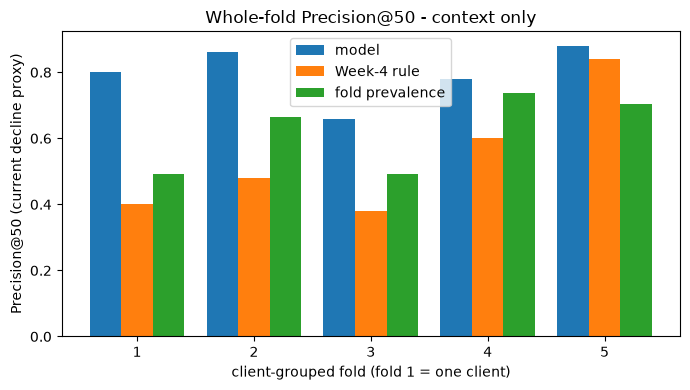

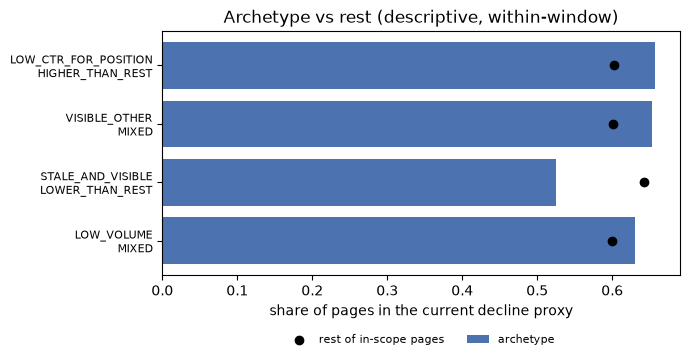

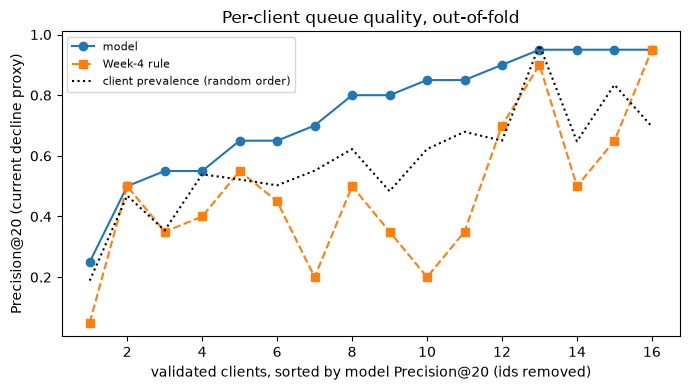

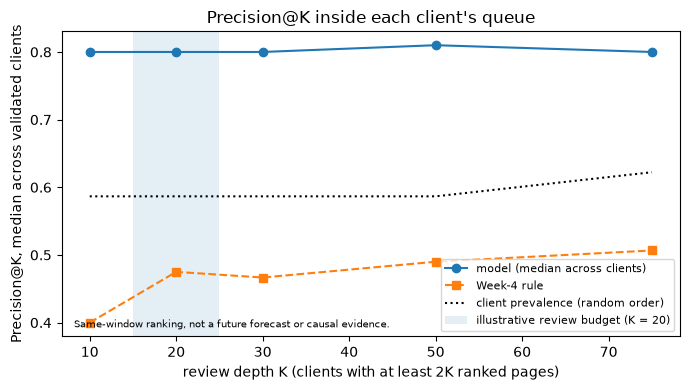

wrote work/outputs/capstone_metrics.json and 4 figures in work/figures/ (aggregates only; do not commit the queue)

Markdown number | this run | status
in-scope pages                             26612 |  2.661e+04 | OK
ranked pages                               16617 |  1.662e+04 | OK
ranked-page clients                           28 |         28 | OK
queued clients without own validation         12 |         12 | OK
in-scope proxy rate                        0.611 |     0.6111 | OK
whole-fold mean model P@50                 0.796 |      0.796 | OK
whole-fold mean rule P@50                   0.54 |       0.54 | OK
whole-fold mean prevalence                 0.618 |     0.6181 | OK
whole-fold mean AUC                        0.595 |      0.595 | OK
validated clients (ranked)                    16 |         16 | OK
AUC median (ranked)                         0.64 |     0.6396 | OK
P@20 median model                            0.8 |        0.8 | OK
P@20 median rule                           0

In [8]:
import hashlib, platform
import matplotlib
import sklearn

FIG_DIR, OUT_DIR = Path("work/figures"), Path("work/outputs")
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- reproducibility: environment, data identity, seeds ----
sha = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
repro = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
         "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
         "data_file": RAW_PATH.name, "data_rows": int(len(df)), "data_columns": int(df.shape[1]),
         "data_sha256_prefix": sha[:16],
         "seeds": {"split_and_model": SEED, "grouped_repeats": list(range(10)), "GroupKFold": "deterministic, no seed"}}
print(json.dumps(repro, indent=2))

# Figure 1 - whole-fold Precision@50 (context only)
fig, ax = plt.subplots(figsize=(7, 4))
x, w = np.arange(1, 6), 0.27
ax.bar(x - w, folds["model_P@50"], w, label="model")
ax.bar(x, folds["rule_P@50"], w, label="Week-4 rule")
ax.bar(x + w, folds["prevalence"], w, label="fold prevalence")
ax.set_xlabel("client-grouped fold (fold 1 = one client)")
ax.set_ylabel("Precision@50 (current decline proxy)")
ax.set_title("Whole-fold Precision@50 - context only")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "capstone_fig_p50_by_fold.png", dpi=150)
plt.show()

# Figure 2 - decline-proxy rate by archetype vs the rest
fig, ax = plt.subplots(figsize=(7, 3.8))
labels = [f"{a}\n{playbook.loc[a, 'evidence']}" for a in playbook.index]
ypos = np.arange(len(playbook))[::-1]
ax.barh(ypos, playbook["proxy_rate"].astype(float), color="#4C72B0", label="archetype")
ax.scatter(playbook["rest_rate"].astype(float), ypos, color="black", zorder=3, label="rest of in-scope pages")
ax.set_yticks(ypos)
ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel("share of pages in the current decline proxy")
ax.set_title("Archetype vs rest (descriptive, within-window)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "capstone_fig_archetype_decline_rate.png", dpi=150)
plt.show()

# Figure 3 - per-client Precision@20, no client ids
pcs = pc_ranked.sort_values("model_P@20").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pcs.index + 1, pcs["model_P@20"], "o-", label="model")
ax.plot(pcs.index + 1, pcs["rule_P@20"], "s--", label="Week-4 rule")
ax.plot(pcs.index + 1, pcs["prevalence"], "k:", label="client prevalence (random order)")
ax.set_xlabel("validated clients, sorted by model Precision@20 (ids removed)")
ax.set_ylabel("Precision@20 (current decline proxy)")
ax.set_title("Per-client queue quality, out-of-fold")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "capstone_fig_per_client_p20.png", dpi=150)
plt.show()

# Figure 4 - Precision@K curve: where the advantage is and where it stops
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve_tbl["K"], curve_tbl["model"], "o-", label="model (median across clients)")
ax.plot(curve_tbl["K"], curve_tbl["rule"], "s--", label="Week-4 rule")
ax.plot(curve_tbl["K"], curve_tbl["prevalence"], "k:", label="client prevalence (random order)")
ax.axvspan(15, 25, alpha=0.12, label="illustrative review budget (K = 20)")
ax.set_xlabel("review depth K (clients with at least 2K ranked pages)")
ax.set_ylabel("Precision@K, median across validated clients")
ax.set_title("Precision@K inside each client's queue")
ax.text(0.02, 0.03, "Same-window ranking, not a future forecast or causal evidence.", transform=ax.transAxes, fontsize=7)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "capstone_fig_precision_at_k.png", dpi=150)
plt.show()

# Metrics - aggregates only
metrics = {
    "data": {"pages": int(len(df)), "clients": int(df["client_id"].nunique()), "in_scope_pages": int(in_scope.sum()),
             "in_scope_share": float(in_scope.mean()), "proxy_rate_all": float(y.mean()), "proxy_rate_in_scope": float(y[in_scope].mean())},
    "final_features": FINAL_FEATURES, "removed_fields": EXCLUDED_WHY,
    "leakage": leak_table.to_dict(orient="records"),
    "grouped_split_10_seeds": {"AUC_mean": float(seed_auc.mean()), "AUC_sd": float(seed_auc.std(ddof=1)),
                               "P@50_mean": float(seed_p50.mean()), "P@50_sd": float(seed_p50.std(ddof=1))},
    "whole_fold_mean": folds[["prevalence", "model_P@20", "model_P@50", "model_P@100", "rule_P@20", "rule_P@50",
                              "rule_P@100", "AUC", "AP"]].mean().to_dict(),
    "per_client_ranked": sum_ranked, "per_client_in_scope_sensitivity": sum_sens,
    "precision_at_k_curve": curve_tbl.to_dict(orient="records"), "c1_boundary": edge_msg,
    "archetypes": playbook.drop(columns="review_prompt").to_dict(orient="index"),
    "no_go_list": policies.to_dict(orient="records"), "monitoring": monitor.to_dict(orient="records"),
    "yield_table_illustrative": yield_table.to_dict(orient="records"),
    "reproducibility": repro,
    "labels": "current decline proxy; same-window ranking, not a future forecast or causal evidence; decision support; not calibrated"}
with open(OUT_DIR / "capstone_metrics.json", "w") as fh:
    json.dump(metrics, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("wrote work/outputs/capstone_metrics.json and 4 figures in work/figures/ (aggregates only; do not commit the queue)")

# ---- numbers quoted in the Markdown vs this run ----
yl = yield_table.set_index(["review_slots", "method"])["mean_yield"]
checks = [
    ("in-scope pages", 26612, int(in_scope.sum()), 0), ("ranked pages", 16617, int(Q["ranked"].sum()), 0),
    ("ranked-page clients", 28, int(Q.loc[Q["ranked"], "client_id"].nunique()), 0),
    ("queued clients without own validation", 12, int(n_queued - len(VALID_IDS)), 0),
    ("in-scope proxy rate", 0.611, float(y[in_scope].mean()), 0.0015),
    ("whole-fold mean model P@50", 0.796, float(folds["model_P@50"].mean()), 0.0015),
    ("whole-fold mean rule P@50", 0.540, float(folds["rule_P@50"].mean()), 0.0015),
    ("whole-fold mean prevalence", 0.618, float(folds["prevalence"].mean()), 0.0015),
    ("whole-fold mean AUC", 0.595, float(folds["AUC"].mean()), 0.0015),
    ("validated clients (ranked)", 16, sum_ranked["clients"], 0), ("AUC median (ranked)", 0.640, sum_ranked["AUC_median"], 0.0015),
    ("P@20 median model", 0.800, sum_ranked["model_P@20"], 0.0015), ("P@20 median rule", 0.475, sum_ranked["rule_P@20"], 0.0015),
    ("prevalence median", 0.587, sum_ranked["prevalence_median"], 0.0015),
    ("model > prevalence share", 0.94, sum_ranked["model>prevalence"], 0.0055), ("model > rule share", 0.875, sum_ranked["model>rule"], 0.0055),
    ("sensitivity clients", 21, sum_sens["clients"], 0), ("sensitivity AUC median", 0.610, sum_sens["AUC_median"], 0.0015),
    ("sensitivity P@20 model", 0.850, sum_sens["model_P@20"], 0.0015),
    ("LOW_CTR pages", 4470, int(playbook.loc["LOW_CTR_FOR_POSITION", "pages"]), 0),
    ("LOW_CTR diff pp", 5.6, float(playbook.loc["LOW_CTR_FOR_POSITION", "diff_pp"]), 0.06),
    ("STALE pages", 7095, int(playbook.loc["STALE_AND_VISIBLE", "pages"]), 0),
    ("STALE diff pp", -11.8, float(playbook.loc["STALE_AND_VISIBLE", "diff_pp"]), 0.06),
    ("VISIBLE_OTHER diff pp", 5.2, float(playbook.loc["VISIBLE_OTHER", "diff_pp"]), 0.06),
    ("yield@20 model queue", 0.741, float(yl[(20, "model queue")]), 0.0015),
    ("yield@20 Week-4 rule", 0.475, float(yl[(20, "Week-4 rule")]), 0.0015),
    ("yield@20 random order", 0.583, float(yl[(20, "random order")]), 0.0015),
    ("AUC IQR q1 (ranked)", 0.607, sum_ranked["AUC_q1"], 0.0015), ("AUC IQR q3 (ranked)", 0.649, sum_ranked["AUC_q3"], 0.0015),
    ("AUC > 0.5 share (ranked)", 1.0, sum_ranked["AUC>0.5"], 0),
    ("sensitivity P@20 rule", 0.450, sum_sens["rule_P@20"], 0.0015), ("sensitivity prevalence", 0.644, sum_sens["prevalence_median"], 0.0015),
    ("whole-fold AUC min", 0.494, float(folds["AUC"].min()), 0.0015), ("whole-fold AUC max", 0.648, float(folds["AUC"].max()), 0.0015),
    ("rule top-50 min largest-client share", 0.82, float(folds["rule_top50_share"].min()), 0.0055),
    ("model top-50 share, folds 2-5 min", 0.46, float(folds.loc[folds["fold"] >= 2, "model_top50_share"].min()), 0.0055),
    ("model top-50 share, folds 2-5 max", 0.78, float(folds.loc[folds["fold"] >= 2, "model_top50_share"].max()), 0.0055),
    ("older than 365d proxy rate", 0.444, float(decay_rows["older than 365 days"]["proxy_rate"]), 0.0015),
    ("older than 365d rest rate", 0.661, float(decay_rows["older than 365 days"]["rest_rate"]), 0.0015),
    ("older than 365d eligible clients", 7, int(decay_rows["older than 365 days"]["clients_eligible"]), 0),
    ("younger than 180d proxy rate", 0.705, float(decay_rows["younger than 180 days"]["proxy_rate"]), 0.0015),
    ("younger than 180d rest rate", 0.548, float(decay_rows["younger than 180 days"]["rest_rate"]), 0.0015),
    ("younger than 180d eligible clients", 10, int(decay_rows["younger than 180 days"]["clients_eligible"]), 0),
    ("LOW_CTR eligible clients", 16, int(playbook.loc["LOW_CTR_FOR_POSITION", "clients_eligible"]), 0),
    ("STALE eligible clients", 12, int(playbook.loc["STALE_AND_VISIBLE", "clients_eligible"]), 0),
    ("out-of-scope pages", 3388, int((~in_scope).sum()), 0),
    ("smallest client (pages)", 3, int(pages_per_client.min()), 0), ("largest client (pages)", 7008, int(pages_per_client.max()), 0),
    ("avg_position == 0 rows", 1205, int((df["avg_position"] == 0).sum()), 0),
    ("word_count missing % (keyword article)", 28.3, float(df.loc[df["content_type"].eq("keyword article"), "word_count"].isna().mean() * 100), 0.06)]
bad = 0
print("\nMarkdown number | this run | status")
for name, quoted, run, tol in checks:
    ok = abs(quoted - run) <= tol
    bad += (not ok)
    print(f"{name:38s} {quoted:>9} | {run:>10.4g} | {'OK' if ok else 'DIFF'}")
props = [("deliberate-leak AUC >= 0.99", float(leak_table.loc[leak_table["test"].str.contains("deliberate"), "AUC"].iloc[0]) >= 0.99),
         ("random-split AUC above grouped-split AUC", float(leak_table.loc[0, "AUC"]) > float(leak_table.loc[4, "AUC"])),
         ("one feature list: 26 features, same in contract and model", FEATURES == FINAL_FEATURES and len(FEATURES) == 26)]
print("\nproperty checks (claims that are not a single number):")
for name, ok in props:
    bad += (not ok)
    print(f"{name:58s} | {'OK' if ok else 'DIFF'}")
total = len(checks) + len(props)
print(f"\n{total - bad} of {total} checks match this run" + ("" if bad == 0 else " - fix the DIFF lines in the Markdown"))

In [9]:
# ---- extended checks: numbers quoted in Sections 1, 3, 4, 5 and 6 that the Section 7 block does not cover ----
lt = leak_table.set_index("test")
ct = curve_tbl.set_index("K")
CURVE_REF = {10: (16, 0.800, 0.400, 0.587, 0.938), 20: (16, 0.800, 0.475, 0.587, 0.938),
             30: (16, 0.800, 0.467, 0.587, 0.938), 50: (16, 0.810, 0.490, 0.587, 1.000),
             75: (13, 0.800, 0.507, 0.622, 1.000)}
ext = [
    ("stress test: CTR-in-band P@20 median (ranked)", 0.825, sum_ranked["ctrband_P@20"], 0.0015),
    ("stress test: model > CTR-in-band share (ranked)", 0.25, sum_ranked["model>ctrband"], 0.0055),
    ("stress test: CTR-in-band > prevalence share (ranked)", 0.94, sum_ranked["ctrband>prevalence"], 0.0055),
    ("stress test: CTR-in-band P@20 median (in scope)", 0.75, sum_sens["ctrband_P@20"], 0.0015),
    ("stress test: model > CTR-in-band share (in scope)", 0.48, sum_sens["model>ctrband"], 0.0055),
    ("stress test: CTR-in-band > prevalence (in scope)", 0.76, sum_sens["ctrband>prevalence"], 0.0055),
    ("leak: clean random AUC", 0.692, float(lt.loc["clean, random split", "AUC"]), 0.0015),
    ("leak: clean random P@50", 0.90, float(lt.loc["clean, random split", "P@50"]), 0.0015),
    ("leak: deliberate leak AUC", 0.999, float(lt.loc["clean + trend_pct (deliberate leak), random split", "AUC"]), 0.0015),
    ("leak: deliberate leak P@50", 1.00, float(lt.loc["clean + trend_pct (deliberate leak), random split", "P@50"]), 0.0015),
    ("leak: window-only AUC", 0.634, float(lt.loc["90-day-window features only, random split", "AUC"]), 0.0015),
    ("leak: window-only P@50", 0.82, float(lt.loc["90-day-window features only, random split", "P@50"]), 0.0015),
    ("leak: static-only AUC", 0.632, float(lt.loc["static features only, random split", "AUC"]), 0.0015),
    ("leak: static-only P@50", 0.86, float(lt.loc["static features only, random split", "P@50"]), 0.0015),
    ("leak: grouped (seed 42) AUC", 0.605, float(lt.loc["clean, client-grouped split", "AUC"]), 0.0015),
    ("leak: grouped (seed 42) P@50", 0.62, float(lt.loc["clean, client-grouped split", "P@50"]), 0.0015),
    ("ten seeds: AUC mean", 0.641, float(seed_auc.mean()), 0.0015),
    ("ten seeds: AUC SD", 0.064, float(seed_auc.std(ddof=1)), 0.0015),
    ("ten seeds: P@50 mean", 0.808, float(seed_p50.mean()), 0.0015),
    ("ten seeds: P@50 SD", 0.068, float(seed_p50.std(ddof=1)), 0.0015),
    ("folds: model P@50 min", 0.66, float(folds["model_P@50"].min()), 0.0015),
    ("folds: model P@50 max", 0.88, float(folds["model_P@50"].max()), 0.0015),
    ("folds: rule P@50 min", 0.38, float(folds["rule_P@50"].min()), 0.0015),
    ("folds: rule P@50 max", 0.84, float(folds["rule_P@50"].max()), 0.0015),
    ("folds: prevalence min", 0.492, float(folds["prevalence"].min()), 0.0015),
    ("folds: prevalence max", 0.737, float(folds["prevalence"].max()), 0.0015),
    ("P1 rows", 478, int(len(p1)), 0),
    ("P1 rows from unvalidated clients", 158, int(p1["f_UNVALIDATED_CLIENT"].sum()), 0),
    ("P1 share from unvalidated clients", 0.331, float(p1["f_UNVALIDATED_CLIENT"].mean()), 0.0015),
    ("ranked share from unvalidated clients", 0.017, float(R["f_UNVALIDATED_CLIENT"].mean()), 0.0015),
    ("flag AGE_UNDER_180D, ranked", 0.403, float(R["f_AGE_UNDER_180D"].mean()), 0.0015),
    ("flag AGE_UNDER_180D, P1", 0.588, float(p1["f_AGE_UNDER_180D"].mean()), 0.0015),
    ("flag ZERO_ENGAGEMENT, ranked", 0.554, float(R["f_ZERO_ENGAGEMENT"].mean()), 0.0015),
    ("flag ZERO_ENGAGEMENT, P1", 0.776, float(p1["f_ZERO_ENGAGEMENT"].mean()), 0.0015),
    ("flag TOP1PCT_IMPRESSIONS, ranked", 0.010, float(R["f_TOP1PCT_IMPRESSIONS"].mean()), 0.0015),
    ("flag TOP1PCT_IMPRESSIONS, P1", 0.004, float(p1["f_TOP1PCT_IMPRESSIONS"].mean()), 0.0015),
    ("P1 archetype: LOW_CTR_FOR_POSITION", 307, int(p1["archetype"].eq("LOW_CTR_FOR_POSITION").sum()), 0),
    ("P1 archetype: STALE_AND_VISIBLE", 88, int(p1["archetype"].eq("STALE_AND_VISIBLE").sum()), 0),
    ("P1 archetype: VISIBLE_OTHER", 83, int(p1["archetype"].eq("VISIBLE_OTHER").sum()), 0),
    ("in-scope pages under 180 days", 0.401, float(S["age"].lt(AGE_T).mean()), 0.0015),
    ("in-scope pages with zero engagement", 0.693, float(S["eng"].eq(0).mean()), 0.0015),
    ("largest client share of pages", 0.234, float(share.iloc[0]), 0.0015),
    ("three largest clients share", 0.433, float(share.iloc[:3].sum()), 0.0015)]
for k, (n_cl, m, r, p, sh) in CURVE_REF.items():
    ext += [(f"curve K={k}: clients", n_cl, int(ct.loc[k, "clients"]), 0),
            (f"curve K={k}: model median", m, float(ct.loc[k, "model"]), 0.0015),
            (f"curve K={k}: rule median", r, float(ct.loc[k, "rule"]), 0.0015),
            (f"curve K={k}: prevalence median", p, float(ct.loc[k, "prevalence"]), 0.0015),
            (f"curve K={k}: model above prevalence", sh, float(ct.loc[k, "model>prevalence"]), 0.0015)]

FOLD_REF = {"clients": [1, 7, 7, 8, 8], "pages": [6983, 5557, 4432, 4857, 4783], "prevalence": [0.492, 0.666, 0.493, 0.737, 0.703],
            "model_P@50": [0.80, 0.86, 0.66, 0.78, 0.88], "rule_P@50": [0.40, 0.48, 0.38, 0.60, 0.84],
            "AUC": [0.641, 0.644, 0.648, 0.494, 0.548], "model_top50_share": [1.00, 0.78, 0.46, 0.50, 0.58],
            "rule_top50_share": [1.00, 1.00, 1.00, 0.82, 0.94]}
for col, vals in FOLD_REF.items():
    for f, v in enumerate(vals, start=1):
        ext.append((f"fold {f}: {col}", v, float(folds.loc[folds["fold"] == f, col].iloc[0]), 0 if col in ("clients", "pages") else 0.0015))
yt = yield_table.set_index(["review_slots", "method"])
YIELD_REF = {(20, "model queue"): (0.741, 14.8, 13.50), (20, "Week-4 rule"): (0.475, 9.5, 21.05), (20, "random order"): (0.583, 11.7, 17.15),
             (50, "model queue"): (0.724, 36.2, 13.82), (50, "Week-4 rule"): (0.498, 24.9, 20.10), (50, "random order"): (0.583, 29.1, 17.15)}
for key, (y_, fnd, cst) in YIELD_REF.items():
    ext += [(f"yield {key}: mean yield", y_, float(yt.loc[key, "mean_yield"]), 0.0015),
            (f"yield {key}: pages found", fnd, float(yt.loc[key, "proxy_declining_found"]), 0.06),
            (f"yield {key}: cost per page found", cst, float(yt.loc[key, "cost_per_page_found"]), 0.006)]
ext += [("sensitivity: model > prevalence share", 0.90, sum_sens["model>prevalence"], 0.0055),
        ("sensitivity: model > rule share", 0.86, sum_sens["model>rule"], 0.0055),
        ("sensitivity: AUC > 0.5 share", 0.90, sum_sens["AUC>0.5"], 0.0055),
        ("sensitivity: AUC IQR q1", 0.574, sum_sens["AUC_q1"], 0.0015), ("sensitivity: AUC IQR q3", 0.645, sum_sens["AUC_q3"], 0.0015),
        ("margin over random order (points)", 21.3, (sum_ranked["model_P@20"] - sum_ranked["prevalence_median"]) * 100, 0.06),
        ("one-signal minus model, median P@20 (points)", 2.5, (sum_ranked["ctrband_P@20"] - sum_ranked["model_P@20"]) * 100, 0.06),
        ("random minus grouped (10 seeds), AUC gap", 0.05, float(lt.loc["clean, random split", "AUC"]) - float(seed_auc.mean()), 0.0055),
        ("random minus grouped (10 seeds), P@50 gap", 0.09, float(lt.loc["clean, random split", "P@50"]) - float(seed_p50.mean()), 0.0055),
        ("AUC gap in seed SDs", 0.8, (float(lt.loc["clean, random split", "AUC"]) - float(seed_auc.mean())) / float(seed_auc.std(ddof=1)), 0.06),
        ("P@50 gap in seed SDs", 1.4, (float(lt.loc["clean, random split", "P@50"]) - float(seed_p50.mean())) / float(seed_p50.std(ddof=1)), 0.06)]
ext_bad = 0
print("Markdown number | this run | status")
for name, quoted, run, tol in ext:
    ok = abs(quoted - run) <= tol
    ext_bad += (not ok)
    print(f"{name:52s} {quoted:>9} | {run:>10.4g} | {'OK' if ok else 'DIFF'}")
ext_props = [("data fingerprint matches the paper (99a2bdada7d15ce0)", repro["data_sha256_prefix"] == "99a2bdada7d15ce0"),
             ("CTR-in-band median P@20 above the model's (ranked), as C4 states", sum_ranked["ctrband_P@20"] > sum_ranked["model_P@20"])]
print("\nproperty checks:")
for name, ok in ext_props:
    ext_bad += (not ok)
    print(f"{name:62s} | {'OK' if ok else 'DIFF'}")
ext_total = len(ext) + len(ext_props)
print(f"\n{ext_total - ext_bad} of {ext_total} extended checks match this run" + ("" if ext_bad == 0 else " - fix the DIFF lines in the Markdown"))

Markdown number | this run | status
stress test: CTR-in-band P@20 median (ranked)            0.825 |      0.825 | OK
stress test: model > CTR-in-band share (ranked)           0.25 |       0.25 | OK
stress test: CTR-in-band > prevalence share (ranked)      0.94 |     0.9375 | OK
stress test: CTR-in-band P@20 median (in scope)           0.75 |       0.75 | OK
stress test: model > CTR-in-band share (in scope)         0.48 |     0.4762 | OK
stress test: CTR-in-band > prevalence (in scope)          0.76 |     0.7619 | OK
leak: clean random AUC                                   0.692 |      0.692 | OK
leak: clean random P@50                                    0.9 |        0.9 | OK
leak: deliberate leak AUC                                0.999 |     0.9991 | OK
leak: deliberate leak P@50                                 1.0 |          1 | OK
leak: window-only AUC                                    0.634 |     0.6336 | OK
leak: window-only P@50                                    0.82 |       0.